# Data analytics track: S3, Glue, Athena and Kinesis

You build a small lending data lake and analyse it with SQL, then push payment events through a stream. Every call goes to AWS Emulator on your machine.

**You will practise:** landing files in S3, describing them in the Glue Data Catalog, querying with Athena, and writing to and reading from a Kinesis stream.

In [1]:
import sys, json, time, datetime as dt
sys.path.insert(0, "../..")          # repository root: emu.py, lab_common.py
import pandas as pd
import matplotlib.pyplot as plt
import emu
from lab_common import *

df = ensure_lake()                   # buckets, loan book in S3, Glue table (safe to re-run)
print("Connected to", emu.settings()["endpoint_url"], "-", len(df), "loans in the lake")

Connected to https://127.0.0.1:9297 - 2000 loans in the lake


## 1. What is in the lake

`ensure_lake()` uploaded `loans.csv` to S3 and registered a `loans` table in Glue. Inspect both.

In [2]:
s3, glue = emu.client("s3"), emu.client("glue")
objects = s3.list_objects_v2(Bucket=LAKE)["Contents"]
print([(o["Key"], o["Size"]) for o in objects])
table = glue.get_table(DatabaseName=DB, Name="loans")["Table"]
print("Location:", table["StorageDescriptor"]["Location"])
pd.DataFrame(table["StorageDescriptor"]["Columns"])

[('loans/loans.csv', 131383)]
Location: s3://bank-lake/loans/


,Name,Type
0,loan_id,string
1,segment,string
2,product,string
3,region,string
4,credit_score,bigint
5,annual_income,bigint
6,loan_amount,bigint
7,dti,double
8,tenure_months,bigint
9,days_past_due,bigint


## 2. Portfolio view by segment

Athena runs this SQL on the emulator's in-process engine and reads the CSV from the emulated S3.

In [3]:
by_segment = run_sql("""
    SELECT segment,
           COUNT(*)                       AS loans,
           SUM(loan_amount)               AS exposure,
           AVG(credit_score)              AS avg_score,
           AVG(CAST(defaulted AS DOUBLE)) AS default_rate
    FROM loans GROUP BY segment ORDER BY default_rate DESC""")
by_segment

,segment,loans,exposure,avg_score,default_rate
0,Self-employed,478,101971000,689.094142,0.271967
1,Salaried,1013,219647000,688.224087,0.239882
2,Agri,193,40860000,688.062176,0.212435
3,SME,316,67957000,694.958861,0.208861


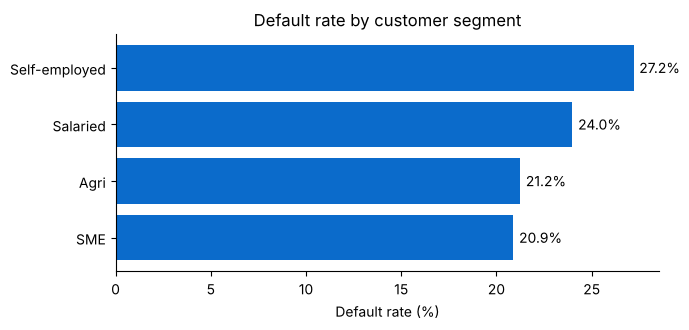

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(by_segment["segment"], by_segment["default_rate"] * 100, color="#0b6bcb")
ax.invert_yaxis(); ax.set_xlabel("Default rate (%)"); ax.set_title("Default rate by customer segment")
for y, v in enumerate(by_segment["default_rate"] * 100):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 3. Risk by credit-score band

A `CASE` expression buckets the scores. Default rate should fall as the band rises.

In [5]:
bands = run_sql("""
    SELECT CASE WHEN credit_score < 600 THEN '1. Below 600'
                WHEN credit_score < 660 THEN '2. 600-659'
                WHEN credit_score < 720 THEN '3. 660-719'
                ELSE '4. 720 and above' END       AS score_band,
           COUNT(*)                               AS loans,
           AVG(CAST(defaulted AS DOUBLE))         AS default_rate,
           AVG(dti)                               AS avg_dti
    FROM loans GROUP BY 1 ORDER BY 1""")
bands

,score_band,loans,default_rate,avg_dti
0,1. Below 600,210,0.576190,0.395643
1,2. 600-659,444,0.335586,0.380453
2,3. 660-719,661,0.223903,0.379029
3,4. 720 and above,685,0.090511,0.372286


## 4. Exposure by product and region

Pivot the SQL result in pandas for a management-style grid (amounts in millions).

In [6]:
grid = run_sql("SELECT product, region, SUM(loan_amount) AS exposure FROM loans GROUP BY product, region")
(grid.pivot(index="product", columns="region", values="exposure") / 1e6).round(1)

region,East,North,South,West
product,,,,
Auto loan,21.0,30.2,29.0,26.0
Credit card,26.0,26.6,27.4,30.8
Home loan,21.3,13.8,14.2,15.5
Personal loan,38.1,35.9,36.7,37.9


## 5. Streaming: payment events through Kinesis

Write repayment events to a stream and read them back, as a downstream consumer would.

In [7]:
kinesis = emu.client("kinesis")
STREAM = "loan-repayments"
if STREAM not in kinesis.list_streams()["StreamNames"]:
    kinesis.create_stream(StreamName=STREAM, ShardCount=1)
    kinesis.get_waiter("stream_exists").wait(StreamName=STREAM, WaiterConfig={"Delay": 1, "MaxAttempts": 20})

events = [{"loan_id": r.loan_id, "amount": int(r.loan_amount / r.tenure_months), "ts": dt.datetime.now(dt.timezone.utc).isoformat()}
          for r in df.sample(20, random_state=1).itertuples()]
attempt("PutRecords", lambda: kinesis.put_records(StreamName=STREAM, Records=[
    {"Data": json.dumps(e).encode(), "PartitionKey": e["loan_id"]} for e in events]))

shard = kinesis.list_shards(StreamName=STREAM)["Shards"][0]["ShardId"]
it = kinesis.get_shard_iterator(StreamName=STREAM, ShardId=shard, ShardIteratorType="TRIM_HORIZON")["ShardIterator"]
received = pd.DataFrame([json.loads(r["Data"]) for r in kinesis.get_records(ShardIterator=it)["Records"]])
print(len(received), "events read back; total repaid", received.amount.sum())
received.tail()

OK      PutRecords
20 events read back; total repaid 141036


,loan_id,amount,ts
15,LN101813,13833,2026-11-17T06:56:31.346904+00:00
16,LN100654,8083,2026-11-17T06:56:31.346908+00:00
17,LN101264,5361,2026-11-17T06:56:31.346911+00:00
18,LN100858,15216,2026-11-17T06:56:31.346915+00:00
19,LN101482,11083,2026-11-17T06:56:31.346918+00:00


## Exercises

1. Write a query for the ten largest loans that are 60 or more days past due.
2. Add a second Glue table over a new S3 prefix (for example `collections/`) and join it to `loans`.
3. Aggregate the Kinesis events by loan and write the result back to S3 as a new CSV.